In [5]:
 %pip install duckdb
 %pip install polars

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [6]:
import duckdb, polars as pl

Data setup and performance foundations
Efficient I/O and caching
- Remote parquet scanning: Use DuckDB’s parquet_scan to query remote files with predicate and projection pushdown.
- HTTP caching: Enable DuckDB’s HTTPFS for caching remote parquet locally to accelerate iterative work.


In [7]:


con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("SET enable_object_cache=true;")

# Links diretos (RAW do GitHub)
files = {
    "ratings": "../Data/ratings.parquet", 
    "movies":  "../Data/movies.parquet",
    "tags":    "../Data/tags.parquet"
}

# Criar views
con.execute(f"CREATE OR REPLACE VIEW ratings AS SELECT * FROM parquet_scan('{files['ratings']}')")
con.execute(f"CREATE OR REPLACE VIEW movies  AS SELECT * FROM parquet_scan('{files['movies']}')")
con.execute(f"CREATE OR REPLACE VIEW tags    AS SELECT * FROM parquet_scan('{files['tags']}')")

In [8]:
import os
import matplotlib.pyplot as plt

# Função auxiliar para consultas
def q(sql: str) -> pl.DataFrame:
    return pl.from_arrow(con.execute(sql).arrow())

# Diretório de saída
output_dir = "figures"
os.makedirs(output_dir, exist_ok=True)

In [9]:
# 1) Nº total de filmes
stat1 = q("""
    SELECT COUNT(*) AS Total_Movies
    FROM movies m   
""")
print(stat1)

shape: (1, 1)
┌──────────────┐
│ Total_Movies │
│ ---          │
│ i64          │
╞══════════════╡
│ 87585        │
└──────────────┘


In [10]:

# 2) Top 10 filmes mais avaliados
stat2 = q("""
    SELECT m.title, COUNT(r.rating) AS n_ratings
    FROM ratings r
    JOIN movies m USING (movieId)
    GROUP BY m.title
    ORDER BY n_ratings DESC
    LIMIT 10
""")

print(stat2)

shape: (10, 2)
┌─────────────────────────────────┬───────────┐
│ title                           ┆ n_ratings │
│ ---                             ┆ ---       │
│ str                             ┆ i64       │
╞═════════════════════════════════╪═══════════╡
│ Shawshank Redemption, The (199… ┆ 102929    │
│ Forrest Gump (1994)             ┆ 100296    │
│ Pulp Fiction (1994)             ┆ 98409     │
│ Matrix, The (1999)              ┆ 93808     │
│ Silence of the Lambs, The (199… ┆ 90330     │
│ Star Wars: Episode IV - A New … ┆ 85010     │
│ Fight Club (1999)               ┆ 77332     │
│ Jurassic Park (1993)            ┆ 75233     │
│ Schindler's List (1993)         ┆ 73849     │
│ Lord of the Rings: The Fellows… ┆ 73122     │
└─────────────────────────────────┴───────────┘


In [11]:
# 2a) Top 10 filmes mais avaliados com seus gêneros
stat2a = q("""
    WITH top_10 AS (
        SELECT m.movieId, m.title, COUNT(r.rating) AS n_ratings
        FROM ratings r
        JOIN movies m USING (movieId)
        GROUP BY m.movieId, m.title
        ORDER BY n_ratings DESC
        LIMIT 10
    )
    SELECT t.title, t.n_ratings, m.genres
    FROM top_10 t
    JOIN movies m USING (movieId)
    ORDER BY t.n_ratings DESC
""")

print("\n=== 2a) Top 10 filmes mais avaliados com gêneros ===")
print(stat2a)



=== 2a) Top 10 filmes mais avaliados com gêneros ===
shape: (10, 3)
┌─────────────────────────────────┬───────────┬─────────────────────────────────┐
│ title                           ┆ n_ratings ┆ genres                          │
│ ---                             ┆ ---       ┆ ---                             │
│ str                             ┆ i64       ┆ str                             │
╞═════════════════════════════════╪═══════════╪═════════════════════════════════╡
│ Shawshank Redemption, The (199… ┆ 102929    ┆ Crime|Drama                     │
│ Forrest Gump (1994)             ┆ 100296    ┆ Comedy|Drama|Romance|War        │
│ Pulp Fiction (1994)             ┆ 98409     ┆ Comedy|Crime|Drama|Thriller     │
│ Matrix, The (1999)              ┆ 93808     ┆ Action|Sci-Fi|Thriller          │
│ Silence of the Lambs, The (199… ┆ 90330     ┆ Crime|Horror|Thriller           │
│ Star Wars: Episode IV - A New … ┆ 85010     ┆ Action|Adventure|Sci-Fi         │
│ Fight Club (1999)          

In [12]:
# 3) Top 10 filmes com melhor média (≥100 avaliações)
stat3 = q("""
    SELECT m.title, COUNT(r.rating) AS n_ratings, AVG(r.rating) AS avg_rating
    FROM ratings r
    JOIN movies m USING (movieId)
    GROUP BY m.title
    HAVING COUNT(r.rating) >= 1000
    ORDER BY avg_rating DESC
    LIMIT 10
""")
print("\n=== 3) Top 10 filmes com melhor média (≥1000 avaliações) ===")
print(stat3)



=== 3) Top 10 filmes com melhor média (≥1000 avaliações) ===
shape: (10, 3)
┌─────────────────────────────────┬───────────┬────────────┐
│ title                           ┆ n_ratings ┆ avg_rating │
│ ---                             ┆ ---       ┆ ---        │
│ str                             ┆ i64       ┆ f64        │
╞═════════════════════════════════╪═══════════╪════════════╡
│ Planet Earth II (2016)          ┆ 1956      ┆ 4.44683    │
│ Planet Earth (2006)             ┆ 2948      ┆ 4.444369   │
│ Band of Brothers (2001)         ┆ 2811      ┆ 4.426539   │
│ Shawshank Redemption, The (199… ┆ 102929    ┆ 4.404614   │
│ Godfather, The (1972)           ┆ 66440     ┆ 4.31703    │
│ Parasite (2019)                 ┆ 11670     ┆ 4.312254   │
│ Blue Planet II (2017)           ┆ 1163      ┆ 4.300086   │
│ Twin Peaks (1989)               ┆ 1140      ┆ 4.298684   │
│ 12 Angry Men (1957)             ┆ 21863     ┆ 4.265311   │
│ Usual Suspects, The (1995)      ┆ 67750     ┆ 4.26507    │
└───────

In [13]:
# 3a) Top 10 filmes com melhor média com seus gêneros
stat3a = q("""
    WITH top_10 AS (
        SELECT m.movieId, m.title, COUNT(r.rating) AS n_ratings, AVG(r.rating) AS avg_rating
        FROM ratings r
        JOIN movies m USING (movieId)
        GROUP BY m.movieId, m.title
        HAVING COUNT(r.rating) >= 100
        ORDER BY avg_rating DESC
        LIMIT 10
    )
    SELECT t.title, t.n_ratings, t.avg_rating, m.genres
    FROM top_10 t
    JOIN movies m USING (movieId)
    ORDER BY t.avg_rating DESC
""")

print("\n=== 3a) Top 10 filmes com melhor média (≥100 avaliações) com gêneros ===")
print(stat3a)


=== 3a) Top 10 filmes com melhor média (≥100 avaliações) com gêneros ===
shape: (10, 4)
┌─────────────────────────────────┬───────────┬────────────┬────────────────────┐
│ title                           ┆ n_ratings ┆ avg_rating ┆ genres             │
│ ---                             ┆ ---       ┆ ---        ┆ ---                │
│ str                             ┆ i64       ┆ f64        ┆ str                │
╞═════════════════════════════════╪═══════════╪════════════╪════════════════════╡
│ Planet Earth II (2016)          ┆ 1956      ┆ 4.44683    ┆ Documentary        │
│ Planet Earth (2006)             ┆ 2948      ┆ 4.444369   ┆ Documentary        │
│ Band of Brothers (2001)         ┆ 2811      ┆ 4.426539   ┆ Action|Drama|War   │
│ Shawshank Redemption, The (199… ┆ 102929    ┆ 4.404614   ┆ Crime|Drama        │
│ Cosmos                          ┆ 615       ┆ 4.330081   ┆ (no genres listed) │
│ Godfather, The (1972)           ┆ 66440     ┆ 4.31703    ┆ Crime|Drama        │
│ Parasit

In [14]:
# 4) Popularidade por gênero
stat4 = q("""
    WITH exploded AS (
        SELECT movieId, UNNEST(STRING_SPLIT(genres, '|')) AS genre
        FROM movies
        WHERE genres IS NOT NULL AND genres <> '(no genres listed)'
    )
    SELECT genre, COUNT(*) AS n_movies
    FROM exploded
    GROUP BY genre
    ORDER BY n_movies DESC
""")
print("\n=== 4) Popularidade por gênero ===")
print(stat4)



=== 4) Popularidade por gênero ===
shape: (19, 2)
┌───────────┬──────────┐
│ genre     ┆ n_movies │
│ ---       ┆ ---      │
│ str       ┆ i64      │
╞═══════════╪══════════╡
│ Drama     ┆ 34175    │
│ Comedy    ┆ 23124    │
│ Thriller  ┆ 11823    │
│ Romance   ┆ 10369    │
│ Action    ┆ 9668     │
│ …         ┆ …        │
│ War       ┆ 2325     │
│ Western   ┆ 1696     │
│ Musical   ┆ 1059     │
│ Film-Noir ┆ 353      │
│ IMAX      ┆ 195      │
└───────────┴──────────┘



=== 5) Atividade de avaliações ao longo do tempo ===
shape: (12, 2)
┌─────────────────────────────┬───────────┐
│ month                       ┆ n_ratings │
│ ---                         ┆ ---       │
│ datetime[μs, Europe/Lisbon] ┆ i64       │
╞═════════════════════════════╪═══════════╡
│ 1995-01-01 00:00:00 CET     ┆ 4         │
│ 1996-01-01 00:00:00 CET     ┆ 42        │
│ 1996-02-01 00:00:00 CET     ┆ 449       │
│ 1996-03-01 00:00:00 CET     ┆ 9184      │
│ 1996-04-01 00:00:00 WEST    ┆ 51177     │
│ …                           ┆ …         │
│ 1996-07-01 00:00:00 WEST    ┆ 216312    │
│ 1996-08-01 00:00:00 WEST    ┆ 209599    │
│ 1996-09-01 00:00:00 WEST    ┆ 146717    │
│ 1996-10-01 00:00:00 WEST    ┆ 186101    │
│ 1996-11-01 00:00:00 WET     ┆ 180014    │
└─────────────────────────────┴───────────┘


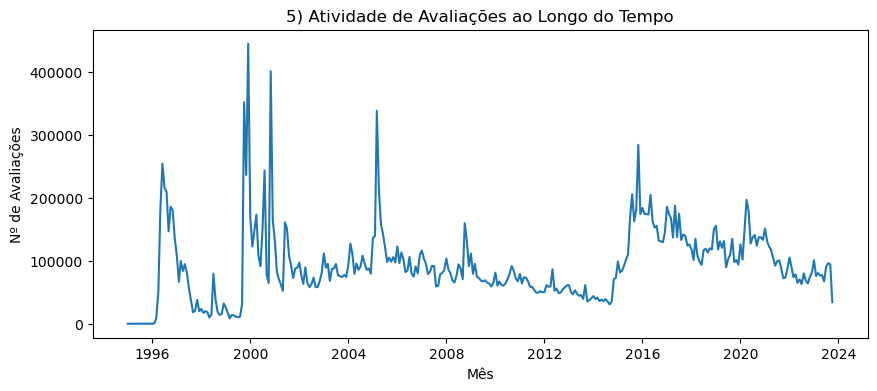

In [15]:
# 5) Atividade de avaliações ao longo do tempo (mensal)
stat5 = q("""
    SELECT DATE_TRUNC('month', TO_TIMESTAMP(timestamp)) AS month,
           COUNT(*) AS n_ratings
    FROM ratings
    GROUP BY month
    ORDER BY month
""")
print("\n=== 5) Atividade de avaliações ao longo do tempo ===")
print(stat5.head(12))
plt.figure(figsize=(10,4))
plt.plot(stat5["month"], stat5["n_ratings"])
plt.title("5) Atividade de Avaliações ao Longo do Tempo")
plt.xlabel("Mês")
plt.ylabel("Nº de Avaliações")
plt.savefig(os.path.join(output_dir, "05_avaliacoes_tempo.png"))
plt.show()


=== 6) Ciclo de vida por ano de lançamento ===
shape: (20, 2)
┌────────────┬───────────┐
│ year_guess ┆ n_ratings │
│ ---        ┆ ---       │
│ i32        ┆ i64       │
╞════════════╪═══════════╡
│ 1874       ┆ 30        │
│ 1878       ┆ 37        │
│ 1880       ┆ 13        │
│ 1882       ┆ 3         │
│ 1883       ┆ 18        │
│ …          ┆ …         │
│ 1897       ┆ 190       │
│ 1898       ┆ 211       │
│ 1899       ┆ 117       │
│ 1900       ┆ 253       │
│ 1901       ┆ 210       │
└────────────┴───────────┘


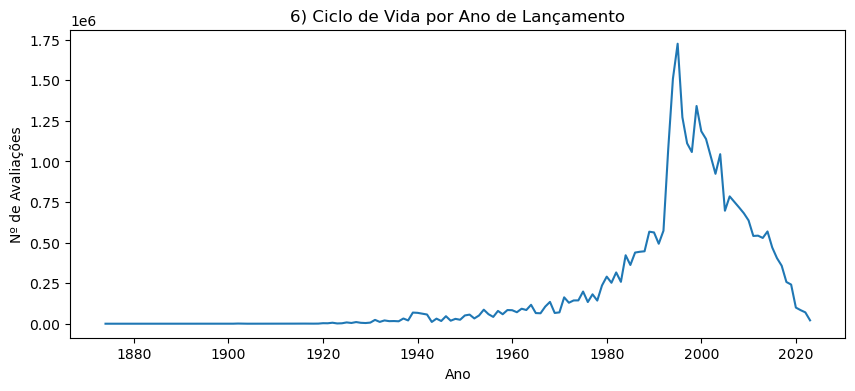

In [16]:
# 6) Ciclo de vida por ano de lançamento
stat6 = q("""
    SELECT CAST(SUBSTRING(m.title, LENGTH(m.title)-4, 4) AS INT) AS year_guess,
           COUNT(r.rating) AS n_ratings
    FROM movies m
    LEFT JOIN ratings r USING (movieId)
    WHERE m.title LIKE '%(%)'
      AND TRY_CAST(SUBSTRING(m.title, LENGTH(m.title)-4, 4) AS INT) IS NOT NULL
    GROUP BY year_guess
    ORDER BY year_guess
""")
print("\n=== 6) Ciclo de vida por ano de lançamento ===")
print(stat6.head(20))
plt.figure(figsize=(10,4))
plt.plot(stat6["year_guess"], stat6["n_ratings"])
plt.title("6) Ciclo de Vida por Ano de Lançamento")
plt.xlabel("Ano")
plt.ylabel("Nº de Avaliações")
plt.savefig(os.path.join(output_dir, "06_ciclo_vida.png"))
plt.show()



=== 7) Co-ocorrência de gêneros ===
shape: (20, 3)
┌───────────┬──────────┬──────┐
│ g1        ┆ g2       ┆ n    │
│ ---       ┆ ---      ┆ ---  │
│ str       ┆ str      ┆ i64  │
╞═══════════╪══════════╪══════╡
│ Comedy    ┆ Drama    ┆ 6081 │
│ Drama     ┆ Romance  ┆ 5943 │
│ Comedy    ┆ Romance  ┆ 4602 │
│ Drama     ┆ Thriller ┆ 4565 │
│ Crime     ┆ Drama    ┆ 3762 │
│ …         ┆ …        ┆ …    │
│ Drama     ┆ War      ┆ 1639 │
│ Action    ┆ Sci-Fi   ┆ 1537 │
│ Animation ┆ Children ┆ 1527 │
│ Animation ┆ Comedy   ┆ 1450 │
│ Adventure ┆ Drama    ┆ 1407 │
└───────────┴──────────┴──────┘


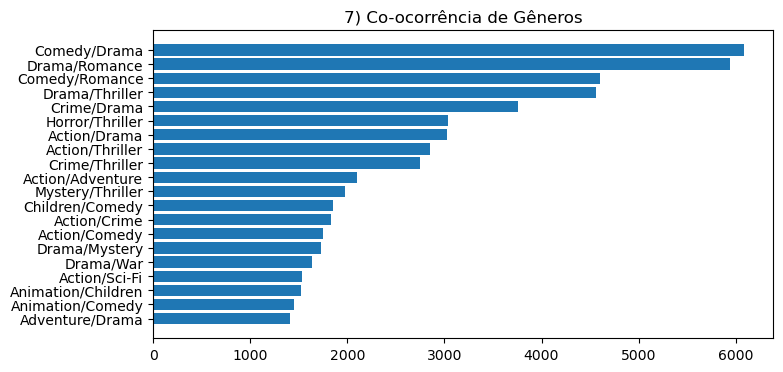

In [18]:
# 7) Co-ocorrência de gêneros
stat7 = q("""
    WITH exploded AS (
        SELECT movieId, UNNEST(STRING_SPLIT(genres, '|')) AS genre
        FROM movies
        WHERE genres IS NOT NULL AND genres <> '(no genres listed)'
    ),
    pairs AS (
        SELECT a.movieId, LEAST(a.genre,b.genre) AS g1, GREATEST(a.genre,b.genre) AS g2
        FROM exploded a
        JOIN exploded b ON a.movieId = b.movieId AND a.genre < b.genre
    )
    SELECT g1, g2, COUNT(*) AS n
    FROM pairs
    GROUP BY g1, g2
    ORDER BY n DESC
    LIMIT 20
""")
print("\n=== 7) Co-ocorrência de gêneros ===")
print(stat7)
plt.figure(figsize=(8,4))
plt.barh([f"{g1}/{g2}" for g1,g2 in zip(stat7["g1"], stat7["g2"])], stat7["n"])
plt.title("7) Co-ocorrência de Gêneros")
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, "09_coocorrencia_generos.png"))
plt.show()



In [19]:
# 8) Média global
stat8 = q("SELECT AVG(rating) AS gmean FROM ratings")
print("\n=== 8) Média global ===")
print(stat8)


=== 8) Média global ===
shape: (1, 1)
┌──────────┐
│ gmean    │
│ ---      │
│ f64      │
╞══════════╡
│ 3.540396 │
└──────────┘


In [20]:
# 9) Distribuição de nº de avaliações por usuário
stat9 = q("""
    SELECT COUNT(*) AS n_ratings
    FROM ratings
    GROUP BY userId
""")
print("=== 9) Distribuição de nº de avaliações por usuário ===")
print(stat9.describe())



=== 9) Distribuição de nº de avaliações por usuário ===
shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ n_ratings  │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 200948.0   │
│ null_count ┆ 0.0        │
│ mean       ┆ 159.246193 │
│ std        ┆ 282.025462 │
│ min        ┆ 20.0       │
│ 25%        ┆ 36.0       │
│ 50%        ┆ 73.0       │
│ 75%        ┆ 167.0      │
│ max        ┆ 33332.0    │
└────────────┴────────────┘


In [ ]:
# 9.a) Análise do utilizador mais ativo
stat9a = q("""
    WITH user_stats AS (
        SELECT userId, COUNT(*) AS n_ratings
        FROM ratings
        GROUP BY userId
    )
    SELECT *
    FROM user_stats
    ORDER BY n_ratings DESC
    LIMIT 1
""")
print("\n=== 9.a) Análise do utilizador mais ativo ===")
print(stat9a)


=== 11.a) Análise do utilizador mais ativo ===
shape: (1, 2)
┌────────┬───────────┐
│ userId ┆ n_ratings │
│ ---    ┆ ---       │
│ i64    ┆ i64       │
╞════════╪═══════════╡
│ 175325 ┆ 33332     │
└────────┴───────────┘


In [21]:
# 9.b) Contagem de reviews por ano para o utilizador mais ativo
stat9b = q("""
    SELECT
        STRFTIME(to_timestamp(timestamp), '%Y') AS review_year,
        COUNT(*) AS n_reviews
    FROM
        ratings
    WHERE
        userId = 175325
    GROUP BY
        review_year
    ORDER BY
        review_year ASC
""")

print("\n=== 9.b) Contagem de reviews por ano para o utilizador mais ativo ===")
print(stat9b)


=== 9.b) Contagem de reviews por ano para o utilizador mais ativo ===
shape: (6, 2)
┌─────────────┬───────────┐
│ review_year ┆ n_reviews │
│ ---         ┆ ---       │
│ str         ┆ i64       │
╞═════════════╪═══════════╡
│ 2015        ┆ 4845      │
│ 2016        ┆ 9945      │
│ 2017        ┆ 4252      │
│ 2018        ┆ 3870      │
│ 2019        ┆ 9287      │
│ 2020        ┆ 1133      │
└─────────────┴───────────┘


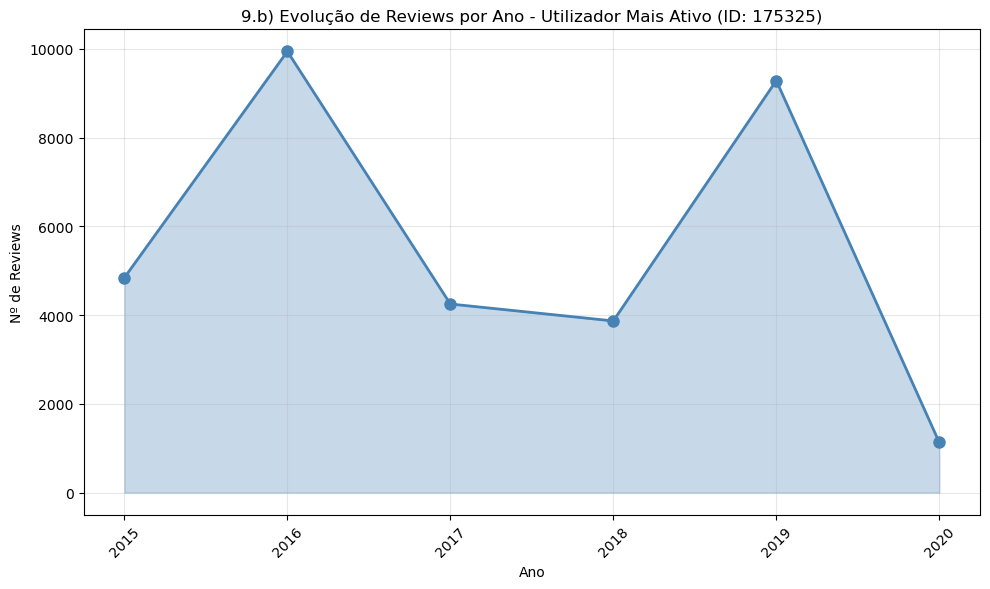

In [24]:
# 9.b) Visualização da evolução de reviews por ano
plt.figure(figsize=(10, 6))
plt.plot(stat9b["review_year"], stat9b["n_reviews"], marker='o', linewidth=2, markersize=8, color='steelblue')
plt.fill_between(range(len(stat9b["review_year"])), stat9b["n_reviews"], alpha=0.3, color='steelblue')
plt.title("9.b) Evolução de Reviews por Ano - Utilizador Mais Ativo (ID: 175325)")
plt.xlabel("Ano")
plt.ylabel("Nº de Reviews")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "9b_evolucao_reviews_usuario.png"), dpi=150)
plt.show()


In [25]:
# 9.c) Primeiros 10 filmes avaliados por este utilizador em 2016
stat9c = q("""
    SELECT
        m.title,
        r.rating,
        STRFTIME(to_timestamp(r.timestamp), '%Y-%m-%d %H:%M:%S') AS review_date
    FROM
        ratings r
    JOIN
        movies m ON r.movieId = m.movieId
    WHERE
        r.userId = 175325
        AND STRFTIME(to_timestamp(r.timestamp), '%Y') = '2016'
    ORDER BY
        r.timestamp ASC
    LIMIT 10
""")

print("\n=== 9.c) Primeiros 10 filmes avaliados em 2016 (Utilizador 175325) ===")
print(stat9c)



=== 9.c) Primeiros 10 filmes avaliados em 2016 (Utilizador 175325) ===
shape: (10, 3)
┌─────────────────────────────────┬────────┬─────────────────────┐
│ title                           ┆ rating ┆ review_date         │
│ ---                             ┆ ---    ┆ ---                 │
│ str                             ┆ f64    ┆ str                 │
╞═════════════════════════════════╪════════╪═════════════════════╡
│ Angelus (2000)                  ┆ 5.0    ┆ 2016-01-02 10:19:54 │
│ Pray the Devil Back to Hell (2… ┆ 5.0    ┆ 2016-01-02 10:19:54 │
│ India's Daughter (2015)         ┆ 5.0    ┆ 2016-01-02 10:19:54 │
│ Old Dark House, The (1932)      ┆ 5.0    ┆ 2016-01-02 10:19:54 │
│ Seymour: An Introduction (2014… ┆ 5.0    ┆ 2016-01-02 10:19:54 │
│ Brooklyn (2015)                 ┆ 4.5    ┆ 2016-01-02 10:19:54 │
│ Taxi (2015)                     ┆ 4.5    ┆ 2016-01-02 10:19:54 │
│ Fanny and Alexander (Fanny och… ┆ 5.0    ┆ 2016-01-02 10:19:54 │
│ Ju Dou (1990)                   ┆ 5.0   

In [26]:
# 9.d) Número de filmes únicos avaliados por este utilizador
stat9d = q("""
    SELECT
        COUNT(DISTINCT movieId) AS n_unique_movies,
        COUNT(*) AS total_reviews
    FROM
        ratings
    WHERE
        userId = 175325
""")

print("\n=== 9.d) Filmes únicos avaliados por utilizador 175325 ===")
print(stat9d)



=== 9.d) Filmes únicos avaliados por utilizador 175325 ===
shape: (1, 2)
┌─────────────────┬───────────────┐
│ n_unique_movies ┆ total_reviews │
│ ---             ┆ ---           │
│ i64             ┆ i64           │
╞═════════════════╪═══════════════╡
│ 33332           ┆ 33332         │
└─────────────────┴───────────────┘


In [28]:
# 9.e) Filmes com as avaliações mais altas dadas por este utilizador
stat9e = q("""
    SELECT
        m.title,
        r.rating,
        STRFTIME(to_timestamp(r.timestamp), '%Y-%m-%d') AS review_date
    FROM
        ratings r 
    JOIN
        movies m ON r.movieId = m.movieId
    WHERE
        r.userId = 175325 and r.rating = 5.0
    ORDER BY
        r.rating DESC,
        r.timestamp DESC
    limit 20
""")

print("\n=== 9.e) Top 20 filmes com as avaliações mais altas (Utilizador 175325) ===")
print(stat9e)



=== 9.e) Top 20 filmes com as avaliações mais altas (Utilizador 175325) ===
shape: (20, 3)
┌─────────────────────────────────┬────────┬─────────────┐
│ title                           ┆ rating ┆ review_date │
│ ---                             ┆ ---    ┆ ---         │
│ str                             ┆ f64    ┆ str         │
╞═════════════════════════════════╪════════╪═════════════╡
│ Sea Gypsies: The Far Side of t… ┆ 5.0    ┆ 2020-06-12  │
│ Shot (2017)                     ┆ 5.0    ┆ 2020-06-12  │
│ When the Mountains Tremble (19… ┆ 5.0    ┆ 2020-06-12  │
│ City War (1988)                 ┆ 5.0    ┆ 2020-06-12  │
│ Radio Stories (1955)            ┆ 5.0    ┆ 2020-06-12  │
│ …                               ┆ …      ┆ …           │
│ The Boxer (1972)                ┆ 5.0    ┆ 2019-10-08  │
│ Destiny (1997)                  ┆ 5.0    ┆ 2019-10-08  │
│ Girls' Club (1936)              ┆ 5.0    ┆ 2019-10-08  │
│ Boxers and Ballerinas (2005)    ┆ 5.0    ┆ 2019-10-04  │
│ The Story of Boys and

In [30]:
# 10  Top 10 Users with the most ratings posted
stat10 = q("""SELECT userId, COUNT(userId) AS n_ratings, AVG(rating) AS average_rating
FROM ratings
GROUP BY userId
ORDER BY n_ratings DESC
LIMIT 10;""")
print(stat10)

shape: (10, 3)
┌────────┬───────────┬────────────────┐
│ userId ┆ n_ratings ┆ average_rating │
│ ---    ┆ ---       ┆ ---            │
│ i64    ┆ i64       ┆ f64            │
╞════════╪═══════════╪════════════════╡
│ 175325 ┆ 33332     ┆ 3.077808       │
│ 17035  ┆ 9577      ┆ 2.567819       │
│ 55653  ┆ 9178      ┆ 3.28029        │
│ 123465 ┆ 9044      ┆ 2.528859       │
│ 171795 ┆ 9016      ┆ 3.181954       │
│ 10202  ┆ 7748      ┆ 3.411655       │
│ 198515 ┆ 7594      ┆ 2.822755       │
│ 49305  ┆ 7488      ┆ 3.208868       │
│ 22744  ┆ 7372      ┆ 2.640193       │
│ 7858   ┆ 7322      ┆ 1.54985        │
└────────┴───────────┴────────────────┘



=== Top 10 Users with the most ratings posted ===
shape: (10, 3)
┌────────┬───────────┬────────────────┐
│ userId ┆ n_ratings ┆ average_rating │
│ ---    ┆ ---       ┆ ---            │
│ i64    ┆ i64       ┆ f64            │
╞════════╪═══════════╪════════════════╡
│ 175325 ┆ 33332     ┆ 3.077808       │
│ 17035  ┆ 9577      ┆ 2.567819       │
│ 55653  ┆ 9178      ┆ 3.28029        │
│ 123465 ┆ 9044      ┆ 2.528859       │
│ 171795 ┆ 9016      ┆ 3.181954       │
│ 10202  ┆ 7748      ┆ 3.411655       │
│ 198515 ┆ 7594      ┆ 2.822755       │
│ 49305  ┆ 7488      ┆ 3.208868       │
│ 22744  ┆ 7372      ┆ 2.640193       │
│ 7858   ┆ 7322      ┆ 1.54985        │
└────────┴───────────┴────────────────┘


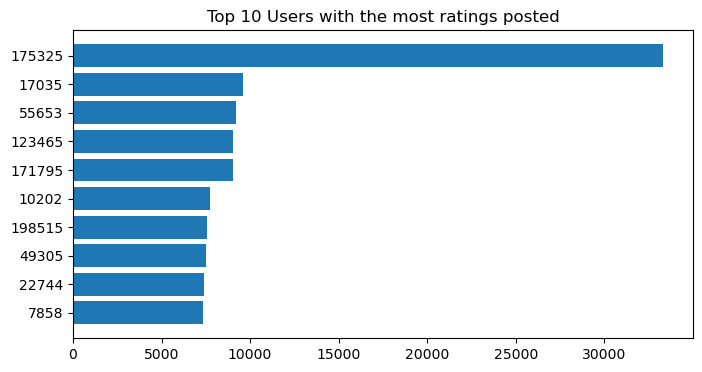

In [31]:
print("\n=== Top 10 Users with the most ratings posted ===")
print(stat10)
plt.figure(figsize=(8,4))
plt.barh(stat10["userId"].cast(str), stat10["n_ratings"])
plt.title("Top 10 Users with the most ratings posted")
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, "10_top10_usuarios.png"))
plt.show()


=== Rating by Genre ===
shape: (19, 2)
┌─────────────┬────────────┐
│ genre       ┆ avg_rating │
│ ---         ┆ ---        │
│ str         ┆ f64        │
╞═════════════╪════════════╡
│ Film-Noir   ┆ 3.915774   │
│ War         ┆ 3.791699   │
│ Crime       ┆ 3.691771   │
│ Documentary ┆ 3.691182   │
│ Drama       ┆ 3.682454   │
│ …           ┆ …          │
│ Sci-Fi      ┆ 3.491699   │
│ Action      ┆ 3.476407   │
│ Children    ┆ 3.439241   │
│ Comedy      ┆ 3.432386   │
│ Horror      ┆ 3.307155   │
└─────────────┴────────────┘


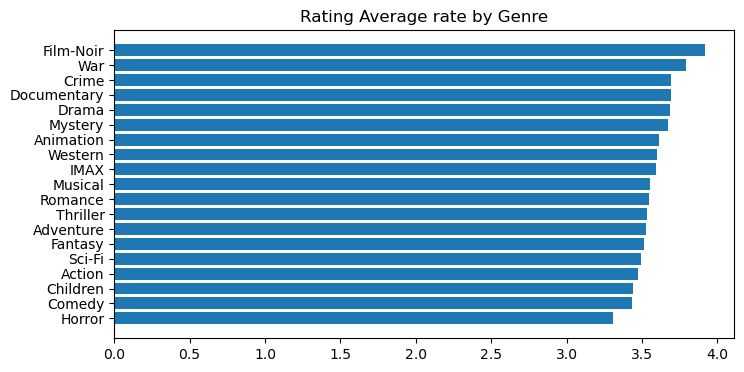

In [32]:
# 11) Rating by Genre
stat11 = q("""
WITH exploded AS (
    SELECT r.rating, genre
    FROM ratings r
    JOIN movies m USING (movieId)
    CROSS JOIN UNNEST(split(m.genres, '|')) AS t(genre)
    WHERE m.genres IS NOT NULL
      AND m.genres <> '(no genres listed)'
)
SELECT 
    genre,
    AVG(rating) AS avg_rating
FROM exploded
GROUP BY genre
ORDER BY avg_rating DESC;
""")
print("\n=== Rating by Genre ===")
print(stat11)
plt.figure(figsize=(8,4))
plt.barh(stat11["genre"], stat11["avg_rating"])
plt.title("Rating Average rate by Genre")
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, "11_media_genero.png"))
plt.show()


=== Number of Evaluations vs Average Rating ===
shape: (100, 3)
┌─────────────────────────────────┬───────────┬────────────┐
│ title                           ┆ n_ratings ┆ avg_rating │
│ ---                             ┆ ---       ┆ ---        │
│ str                             ┆ i64       ┆ f64        │
╞═════════════════════════════════╪═══════════╪════════════╡
│ Shawshank Redemption, The (199… ┆ 102929    ┆ 4.404614   │
│ Forrest Gump (1994)             ┆ 100296    ┆ 4.052744   │
│ Pulp Fiction (1994)             ┆ 98409     ┆ 4.196969   │
│ Matrix, The (1999)              ┆ 93808     ┆ 4.156437   │
│ Silence of the Lambs, The (199… ┆ 90330     ┆ 4.148367   │
│ …                               ┆ …         ┆ …          │
│ Iron Man (2008)                 ┆ 36468     ┆ 3.815139   │
│ Up (2009)                       ┆ 36382     ┆ 3.950443   │
│ Big Lebowski, The (1998)        ┆ 36349     ┆ 3.992531   │
│ Being John Malkovich (1999)     ┆ 36151     ┆ 3.933888   │
│ Babe (1995)       

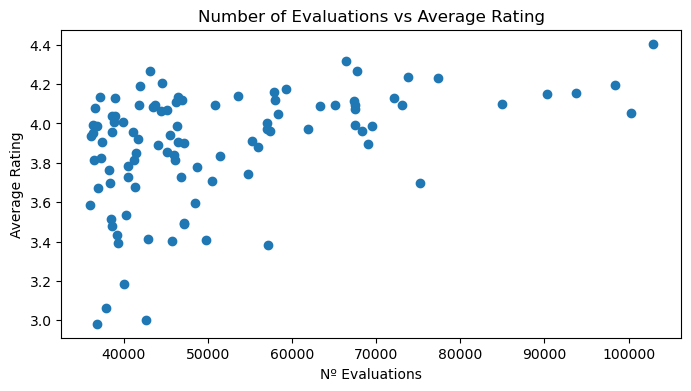

In [35]:
# 12) Number of Evaluations vs Average Rating
stat12 = q("""
SELECT 
    m.title,
    COUNT(r.rating) AS n_ratings,
    AVG(r.rating) AS avg_rating
FROM ratings r
JOIN movies m ON r.movieId = m.movieId
GROUP BY m.title
ORDER BY n_ratings DESC
LIMIT 100;
""")
print("\n=== Number of Evaluations vs Average Rating ===")
print(stat12)
plt.figure(figsize=(8,4))
plt.scatter(stat12["n_ratings"], stat12["avg_rating"])
plt.title("Number of Evaluations vs Average Rating")
plt.xlabel("Nº Evaluations")
plt.ylabel("Average Rating")
plt.savefig(os.path.join(output_dir, "Number of evaluations vs Average Rating.png"))
plt.show()



=== Movies with Highest Rating Standard Deviation (at least 500 ratings) ===
shape: (15, 3)
┌─────────────────────────────────┬──────┬──────────┐
│ title                           ┆ n    ┆ std      │
│ ---                             ┆ ---  ┆ ---      │
│ str                             ┆ i64  ┆ f64      │
╞═════════════════════════════════╪══════╪══════════╡
│ Room, The (2003)                ┆ 1179 ┆ 1.642787 │
│ Fifty Shades Darker (2017)      ┆ 672  ┆ 1.489915 │
│ What the #$*! Do We Know!? (a.… ┆ 729  ┆ 1.475128 │
│ Twilight Saga: Breaking Dawn -… ┆ 2362 ┆ 1.457563 │
│ High School Musical 3: Senior … ┆ 871  ┆ 1.449172 │
│ …                               ┆ …    ┆ …        │
│ Sex and the City 2 (2010)       ┆ 912  ┆ 1.377679 │
│ Twilight Saga: New Moon, The (… ┆ 4038 ┆ 1.37271  │
│ Hannah Montana: The Movie (200… ┆ 587  ┆ 1.369214 │
│ High School Musical 2 (2007)    ┆ 1064 ┆ 1.366236 │
│ Movie 43 (2013)                 ┆ 844  ┆ 1.359864 │
└─────────────────────────────────┴──────┴─

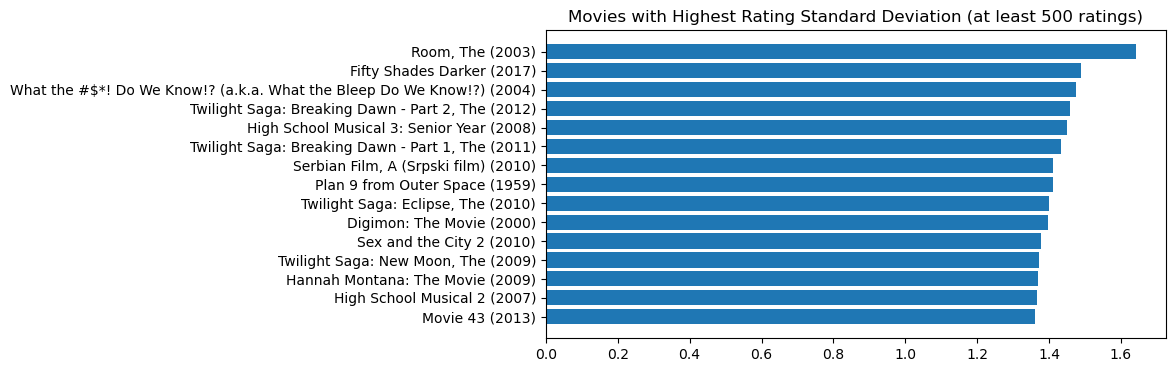

In [36]:
#Movies with Highest Rating Standard Deviation (at least 500 ratings)
stat13 = q("""
SELECT 
    m.title,
    COUNT(r.rating) AS n,
    stddev(r.rating) AS std
FROM ratings r
JOIN movies m ON r.movieId = m.movieId
GROUP BY m.title
HAVING COUNT(r.rating) >= 500
ORDER BY std DESC
LIMIT 15;
""")
print("\n=== Movies with Highest Rating Standard Deviation (at least 500 ratings) ===")
print(stat13)
plt.figure(figsize=(8,4))
plt.barh(stat13["title"], stat13["std"])
plt.title("Movies with Highest Rating Standard Deviation (at least 500 ratings)")
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, "Movies with Highest Rating Standard Deviation (at least 500 ratings).png"))
plt.show()


=== Top 20 Tags with Highest Average Movie Rating (at least 50 ratings) ===
shape: (20, 3)
┌───────────────────────────┬────────────┬─────┐
│ tag                       ┆ avg_rating ┆ n   │
│ ---                       ┆ ---        ┆ --- │
│ str                       ┆ f64        ┆ i64 │
╞═══════════════════════════╪════════════╪═════╡
│ favorite                  ┆ 4.858434   ┆ 166 │
│ brilliant                 ┆ 4.657143   ┆ 105 │
│ great screenplay          ┆ 4.627778   ┆ 90  │
│ great writing             ┆ 4.621622   ┆ 148 │
│ masterpiece               ┆ 4.604809   ┆ 811 │
│ …                         ┆ …          ┆ …   │
│ excellent use of dialogue ┆ 4.543103   ┆ 58  │
│ rewatch worthy            ┆ 4.541237   ┆ 97  │
│ good science              ┆ 4.539409   ┆ 203 │
│ sounds                    ┆ 4.539216   ┆ 51  │
│ mindblowing               ┆ 4.527273   ┆ 55  │
└───────────────────────────┴────────────┴─────┘


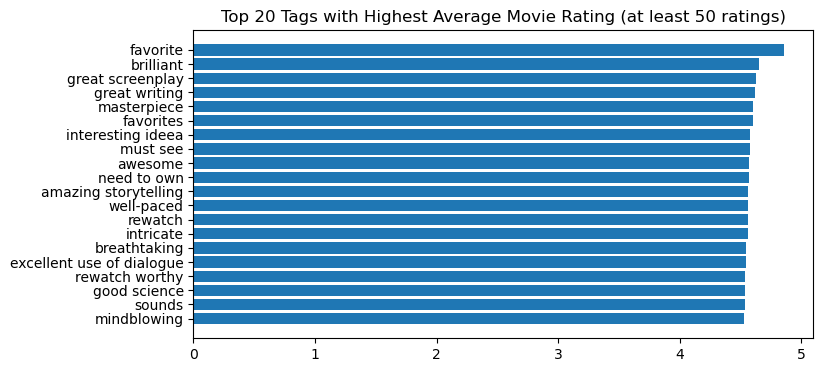

In [38]:
# 14) Top 20 Tags with Highest Average Movie Rating (at least 50 ratings)
stat14 = q("""
SELECT 
    LOWER(trim(t.tag)) AS tag,
    AVG(r.rating) AS avg_rating,
    COUNT(*) AS n
FROM ratings r
JOIN tags t 
    ON r.userId = t.userId 
   AND r.movieId = t.movieId
GROUP BY 1
HAVING COUNT(*) >= 50
ORDER BY avg_rating DESC
LIMIT 20;
""")
print("\n=== Top 20 Tags with Highest Average Movie Rating (at least 50 ratings) ===")
print(stat14)
plt.figure(figsize=(8,4))
plt.barh(stat14["tag"], stat14["avg_rating"])
plt.title("Top 20 Tags with Highest Average Movie Rating (at least 50 ratings)")
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, "Top 20 Tags with Highest Average Movie Rating (at least 50 ratings).png"))
plt.show()


=== Top 20 Tags with Lowest Average Movie Rating (at least 50 ratings) ===
shape: (20, 3)
┌──────────────────────────┬────────────┬─────┐
│ tag                      ┆ avg_rating ┆ n   │
│ ---                      ┆ ---        ┆ --- │
│ str                      ┆ f64        ┆ i64 │
╞══════════════════════════╪════════════╪═════╡
│ terrible                 ┆ 1.03125    ┆ 64  │
│ waste of time            ┆ 1.207547   ┆ 53  │
│ unfunny                  ┆ 1.384106   ┆ 151 │
│ bad remake               ┆ 1.62       ┆ 50  │
│ stupid plot              ┆ 1.69375    ┆ 80  │
│ …                        ┆ …          ┆ …   │
│ bad adaptation           ┆ 1.931507   ┆ 73  │
│ interracial relationship ┆ 1.93956    ┆ 182 │
│ terrible acting          ┆ 1.977778   ┆ 90  │
│ poor dialogue            ┆ 1.981818   ┆ 55  │
│ woke                     ┆ 1.985075   ┆ 67  │
└──────────────────────────┴────────────┴─────┘


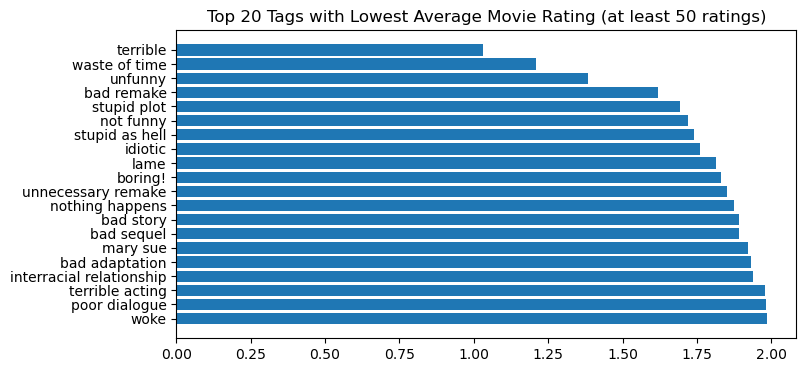

In [39]:
# 15) Top 20 Tags with Lowest Average Movie Rating (at least 50 ratings)
stat15 = q("""
SELECT 
    LOWER(trim(t.tag)) AS tag,
    AVG(r.rating) AS avg_rating,
    COUNT(*) AS n
FROM ratings r
JOIN tags t
    ON r.userId = t.userId
   AND r.movieId = t.movieId
GROUP BY 1
HAVING COUNT(*) >= 50
ORDER BY avg_rating ASC
LIMIT 20;
""")
print("\n=== Top 20 Tags with Lowest Average Movie Rating (at least 50 ratings) ===")
print(stat15)
plt.figure(figsize=(8,4))
plt.barh(stat15["tag"], stat15["avg_rating"])
plt.title("Top 20 Tags with Lowest Average Movie Rating (at least 50 ratings)")
plt.gca().invert_yaxis()
plt.savefig(os.path.join(output_dir, "24_tags_baixas.png"))
plt.show()

In [43]:
# 16 - Nota média por década 
stat16 = q("""
SELECT
    r.movieId,
    m.title,
    (FLOOR(EXTRACT(year FROM to_timestamp(r.timestamp)) / 10) * 10) AS decade,
    AVG(r.rating) AS med_rating,
    COUNT(*) AS qtd_ratings
FROM ratings AS r
LEFT JOIN movies AS m ON m.movieId = r.movieId
GROUP BY r.movieId, m.title, (FLOOR(EXTRACT(year FROM to_timestamp(r.timestamp)) / 10) * 10)
ORDER BY m.title, decade, qtd_ratings DESC, med_rating DESC
""")
print("\n=== 16 - Nota média por década ===")
print(stat16)


=== 16 - Nota média por década ===
shape: (145_457, 5)
┌─────────┬─────────────────────────────────┬────────┬────────────┬─────────────┐
│ movieId ┆ title                           ┆ decade ┆ med_rating ┆ qtd_ratings │
│ ---     ┆ ---                             ┆ ---    ┆ ---        ┆ ---         │
│ i64     ┆ str                             ┆ f64    ┆ f64        ┆ i64         │
╞═════════╪═════════════════════════════════╪════════╪════════════╪═════════════╡
│ 210479  ┆  (2019)                         ┆ 2010.0 ┆ 0.75       ┆ 2           │
│ 210479  ┆  (2019)                         ┆ 2020.0 ┆ 2.772727   ┆ 33          │
│ 208297  ┆ "BLOW THE NIGHT!" Let's Spend … ┆ 2010.0 ┆ 3.0        ┆ 1           │
│ 208297  ┆ "BLOW THE NIGHT!" Let's Spend … ┆ 2020.0 ┆ 1.0        ┆ 1           │
│ 51372   ┆ "Great Performances" Cats (199… ┆ 2000.0 ┆ 2.85       ┆ 30          │
│ …       ┆ …                               ┆ …      ┆ …          ┆ …           │
│ 221466  ┆ 茶叶之旅 (2014)                 ┆ 

In [44]:
# 16b -  Filme mais avaliado por década (Top 1 por década) - Fica, mas não usamos gráfico, só tabela, juntamos a evolução por ano (ponto 5)
stat16b = q("""
WITH MAIN_QUERY AS 
(
    SELECT 
        m.title, 
        (FLOOR(EXTRACT(year FROM to_timestamp(r.timestamp)) / 10) * 10) AS decade, 
        AVG(r.rating) AS med_rating, 
        COUNT(*) AS qtd_ratings,
        ROW_NUMBER() OVER(PARTITION BY (FLOOR(EXTRACT(year FROM to_timestamp(r.timestamp)) / 10) * 10) ORDER BY COUNT(*) DESC, AVG(r.rating) DESC) AS RN
    FROM ratings AS r
    LEFT JOIN movies AS m ON m.movieId = r.movieId
    GROUP BY m.title, (FLOOR(EXTRACT(year FROM to_timestamp(r.timestamp)) / 10) * 10)
)
SELECT 
    decade,
    title,
    med_rating,
    qtd_ratings
FROM MAIN_QUERY
WHERE RN = 1
ORDER BY decade
""")
print("\n=== 16b -  Filme mais avaliado por década (Top 1 por década) ===")
print(stat16b)


=== 16b -  Filme mais avaliado por década (Top 1 por década) ===
shape: (4, 4)
┌────────┬─────────────────────┬────────────┬─────────────┐
│ decade ┆ title               ┆ med_rating ┆ qtd_ratings │
│ ---    ┆ ---                 ┆ ---        ┆ ---         │
│ f64    ┆ str                 ┆ f64        ┆ i64         │
╞════════╪═════════════════════╪════════════╪═════════════╡
│ 1990.0 ┆ Pulp Fiction (1994) ┆ 4.070495   ┆ 25179       │
│ 2000.0 ┆ Matrix, The (1999)  ┆ 4.209053   ┆ 33281       │
│ 2010.0 ┆ Matrix, The (1999)  ┆ 4.117752   ┆ 42857       │
│ 2020.0 ┆ Inception (2010)    ┆ 4.163378   ┆ 15103       │
└────────┴─────────────────────┴────────────┴─────────────┘


In [45]:
# 17 - Filmes com maior proporção de notas 5 - juntar ao ponto 2 e 3 
stat17 = q("""
WITH filmes_5 AS (
    SELECT 
        title, 
        genres,
        AVG(rating) as med_rating,
        SUM(CASE WHEN rating >=5 THEN 1 ELSE 0 END) qtd_ratings_5,
        count(*) qtd_ratings
    FROM ratings as r
    left join movies as m on m.movieid = r.movieid
    group by title, genres
)
SELECT *, ((qtd_ratings_5*1.0/qtd_ratings)*100.0)  as prct FROM filmes_5
ORDER BY qtd_ratings_5 DESC
LIMIT 10
""")
print("\n=== 17- Filmes com maior proporção de notas 5 ===")
print(stat17)


=== 17- Filmes com maior proporção de notas 5 ===
shape: (10, 6)
┌─────────────────────┬─────────────────────┬────────────┬───────────────┬─────────────┬───────────┐
│ title               ┆ genres              ┆ med_rating ┆ qtd_ratings_5 ┆ qtd_ratings ┆ prct      │
│ ---                 ┆ ---                 ┆ ---        ┆ ---           ┆ ---         ┆ ---       │
│ str                 ┆ str                 ┆ f64        ┆ decimal[38,0] ┆ i64         ┆ f64       │
╞═════════════════════╪═════════════════════╪════════════╪═══════════════╪═════════════╪═══════════╡
│ Shawshank           ┆ Crime|Drama         ┆ 4.404614   ┆ 49079         ┆ 102929      ┆ 47.682383 │
│ Redemption, The     ┆                     ┆            ┆               ┆             ┆           │
│ (199…               ┆                     ┆            ┆               ┆             ┆           │
│ Pulp Fiction (1994) ┆ Comedy|Crime|Drama| ┆ 4.196969   ┆ 39248         ┆ 98409       ┆ 39.882531 │
│                     ┆ T

In [46]:
# 17.a- Filmes com maior proporção de notas 1
stat17a = q("""
WITH filmes_1 AS (
    SELECT 
        title, 
        genres,
        AVG(rating) as med_rating,
        SUM(CASE WHEN rating <=1 THEN 1 ELSE 0 END) qtd_ratings_1,
        count(*) qtd_ratings
    FROM ratings as r
    left join movies as m on m.movieid = r.movieid
    group by title, genres
)
SELECT *, ((qtd_ratings_1*1.0/qtd_ratings)*100.0)  as prct FROM filmes_1
ORDER BY qtd_ratings_1 DESC;
""")
print("\n=== 17.a- Filmes com maior proporção de notas 1 ===")   
print(stat17a)



=== 17.a- Filmes com maior proporção de notas 1 ===
shape: (84_402, 6)
┌─────────────────────┬─────────────────────┬────────────┬───────────────┬─────────────┬───────────┐
│ title               ┆ genres              ┆ med_rating ┆ qtd_ratings_1 ┆ qtd_ratings ┆ prct      │
│ ---                 ┆ ---                 ┆ ---        ┆ ---           ┆ ---         ┆ ---       │
│ str                 ┆ str                 ┆ f64        ┆ decimal[38,0] ┆ i64         ┆ f64       │
╞═════════════════════╪═════════════════════╪════════════╪═══════════════╪═════════════╪═══════════╡
│ Dumb & Dumber (Dumb ┆ Adventure|Comedy    ┆ 2.982691   ┆ 5095          ┆ 36802       ┆ 13.844356 │
│ and Dumber…         ┆                     ┆            ┆               ┆             ┆           │
│ Ace Ventura: Pet    ┆ Comedy              ┆ 3.001755   ┆ 4695          ┆ 42728       ┆ 10.988111 │
│ Detective (19…      ┆                     ┆            ┆               ┆             ┆           │
│ Ace Ventura: When

In [47]:
# 18- Variação de filmes ao longos dos anos
stat18 = q("""
WITH filmes AS (
    SELECT 
        m.title,
        m.genres,
        EXTRACT(year FROM to_timestamp(r.timestamp)) AS ano,
        AVG(r.rating) AS med_rating,
        COUNT(*) AS qtd_ratings
    FROM ratings AS r
    LEFT JOIN movies AS m ON m.movieId = r.movieId
    GROUP BY m.title, m.genres, EXTRACT(year FROM to_timestamp(r.timestamp))
)
SELECT *,
       med_rating - LAG(med_rating) OVER (ORDER BY title, ano) AS var_med_rating,
       qtd_ratings - LAG(qtd_ratings) OVER (ORDER BY title, ano) AS var_qtd_rating
FROM filmes
--ORDER BY title, ano DESC
""")
print("\n=== 18- Variação de filmes ao longos dos anos ===")
print(stat18)


=== 18- Variação de filmes ao longos dos anos ===
shape: (487_766, 7)
┌────────────────┬───────────────┬──────┬────────────┬─────────────┬───────────────┬───────────────┐
│ title          ┆ genres        ┆ ano  ┆ med_rating ┆ qtd_ratings ┆ var_med_ratin ┆ var_qtd_ratin │
│ ---            ┆ ---           ┆ ---  ┆ ---        ┆ ---         ┆ g             ┆ g             │
│ str            ┆ str           ┆ i64  ┆ f64        ┆ i64         ┆ ---           ┆ ---           │
│                ┆               ┆      ┆            ┆             ┆ f64           ┆ i64           │
╞════════════════╪═══════════════╪══════╪════════════╪═════════════╪═══════════════╪═══════════════╡
│  (2019)        ┆ Drama|Thrille ┆ 2019 ┆ 0.75       ┆ 2           ┆ null          ┆ null          │
│                ┆ r             ┆      ┆            ┆             ┆               ┆               │
│  (2019)        ┆ Drama|Thrille ┆ 2020 ┆ 2.833333   ┆ 18          ┆ 2.083333      ┆ 16            │
│                ┆ r